# 03 · Exploratory data analysis (KB)

**Job:** describe the 10,000 KB images and 50,000 captions. Nothing here changes the data.

| Topic | Main output in `results/eda/` |
|---|---|
| Caption length, vocabulary | `caption_statistics.json` |
| Word frequency | `word_frequency_statistics.json`, `top_20_content_words.csv` |
| Parts of speech (spaCy) | `pos_distribution.csv` |
| Object categories (COCO labels) | `object_statistics.json`, `top_50_object_categories.csv` |
| Object pairs | `top_20_object_pairs.csv`, `object_cooccurrence_heatmap.png` |
| Scene complexity | `scene_complexity_stats.json` |
| Colours and context (caption keywords) | `colors_caption_cues.csv`, `contexts_caption_cues.csv` |
| Box geometry | `spatial_bbox_proxy_counts.csv` |

Also writes `data/metadata/kb_object_metadata.csv` (objects per KB image), used by notebook 06.

Run on Google Colab. All files are read from and written to `MyDrive/G9_Hybrid_RAG/`. Needs notebook 02. No GPU needed.

## 1. Connect Drive

In [ ]:
from google.colab import drive
from pathlib import Path

# Step 1: Mount Google Drive
drive.mount("/content/drive")

# Step 2: Define project paths
PROJECT_DIR = Path("/content/drive/MyDrive/G9_Hybrid_RAG")

DATA_DIR = PROJECT_DIR / "data"
SPLITS_DIR = DATA_DIR / "splits"
ANNOTATIONS_DIR = DATA_DIR / "approved_annotations"
ARCHIVE_DIR = DATA_DIR / "images_archives"

# Step 3: Check existing files
required_paths = {
    "Project folder": PROJECT_DIR,
    "Image manifest": SPLITS_DIR / "image_manifest.csv",
    "Split IDs": SPLITS_DIR / "split_ids.json",
    "KB annotations": ANNOTATIONS_DIR / "kb_captions.json",
    "KB image ZIP": ARCHIVE_DIR / "knowledge_base/part_001.zip",
    "Validation image ZIP": ARCHIVE_DIR / "validation/part_001.zip",
    "Test image ZIP": ARCHIVE_DIR / "test/part_001.zip",
}

for name, path in required_paths.items():
    status = "✅ FOUND" if path.exists() else "❌ MISSING"
    print(f"{status} — {name}")

print("\n✅ Initial path check finished!")

Mounted at /content/drive
✅ FOUND — Project folder
✅ FOUND — Image manifest
✅ FOUND — Split IDs
✅ FOUND — KB annotations
✅ FOUND — KB image ZIP
✅ FOUND — Validation image ZIP
✅ FOUND — Test image ZIP

✅ Initial path check finished!


## 2. Caption length and vocabulary

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Step 1: Load our cleaned captions
csv_path = (
    DATA_DIR / "preprocessed_captions"
    / "kb_captions_retrieval.csv"
)

df = pd.read_csv(csv_path)

# Step 2: Validate dataset
assert len(df) == 50000
assert df["image_id"].nunique() == 10000
assert df["caption_clean"].notna().all()

# Step 3: Tokenize captions
df["tokens"] = df["caption_clean"].apply(
    lambda text: text.split()
)

# Step 4: Calculate caption lengths
df["caption_length"] = df["tokens"].apply(len)

# Step 5: Calculate vocabulary
word_counts = Counter(
    word
    for tokens in df["tokens"]
    for word in tokens
)

# Step 6: Display statistics
print("===== CAPTION STATISTICS =====")
print("Total captions:", len(df))
print("Total images:", df["image_id"].nunique())
print("Average length:", round(df["caption_length"].mean(), 2))
print("Median length:", df["caption_length"].median())
print("Minimum length:", df["caption_length"].min())
print("Maximum length:", df["caption_length"].max())
print("Vocabulary size:", len(word_counts))

print("\n✅ Caption statistics completed!")

===== CAPTION STATISTICS =====
Total captions: 50000
Total images: 10000
Average length: 10.49
Median length: 10.0
Minimum length: 6
Maximum length: 46
Vocabulary size: 9770

✅ Caption statistics completed!


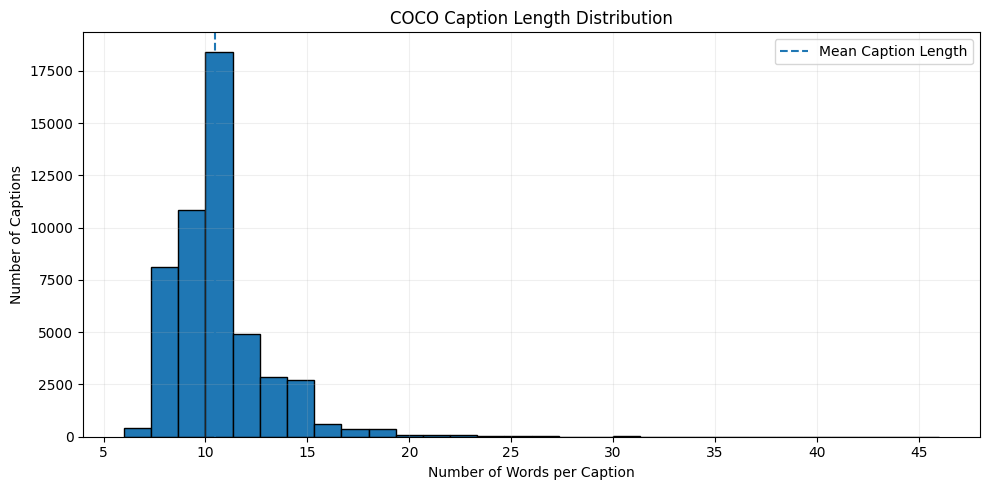

✅ Histogram saved successfully!


In [ ]:
# Step 1: Create histogram
plt.figure(figsize=(10, 5))

plt.hist(
    df["caption_length"],
    bins=30,
    edgecolor="black"
)

# Step 2: Add labels
plt.title("COCO Caption Length Distribution")
plt.xlabel("Number of Words per Caption")
plt.ylabel("Number of Captions")

# Step 3: Add average line
plt.axvline(
    df["caption_length"].mean(),
    linestyle="--",
    label="Mean Caption Length"
)

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()

# Step 4: Save figure
eda_dir = PROJECT_DIR / "results" / "eda"
eda_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    eda_dir / "caption_length_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Histogram saved successfully!")

In [ ]:
import json
import pandas as pd

# Step 1: Create EDA output directory
eda_dir = PROJECT_DIR / "results" / "eda"
eda_dir.mkdir(parents=True, exist_ok=True)

# Step 2: Collect numerical statistics
caption_stats = {
    "dataset": "COCO 2017 - G9 Knowledge Base",
    "total_images": int(df["image_id"].nunique()),
    "total_captions": int(len(df)),
    "total_words": int(df["caption_length"].sum()),

    "average_caption_length": round(
        float(df["caption_length"].mean()), 2
    ),
    "median_caption_length": float(
        df["caption_length"].median()
    ),
    "min_caption_length": int(
        df["caption_length"].min()
    ),
    "max_caption_length": int(
        df["caption_length"].max()
    ),
    "std_caption_length": round(
        float(df["caption_length"].std()), 2
    ),
    "vocabulary_size": int(len(word_counts)),
    "tokenization": "Whitespace split on cleaned captions"
}

# Step 3: Save summary to JSON
json_path = eda_dir / "caption_statistics.json"

with open(json_path, "w", encoding="utf-8") as f:
    json.dump(caption_stats, f, indent=4)

# Step 4: Save summary to CSV
csv_stats_path = eda_dir / "caption_statistics.csv"

pd.DataFrame(
    [caption_stats]
).to_csv(csv_stats_path, index=False)

# Step 5: Save caption lengths for future analysis
lengths_path = eda_dir / "caption_lengths.csv"

df[
    ["image_id", "annotation_id", "caption_length"]
].to_csv(lengths_path, index=False)

# Step 6: Save 20 most frequent words
top_words_path = eda_dir / "top_20_words.csv"

top_words_df = pd.DataFrame(
    word_counts.most_common(20),
    columns=["word", "frequency"]
)

top_words_df.to_csv(
    top_words_path,
    index=False
)

# Step 7: Show saved statistics
print("===== SAVED CAPTION STATISTICS =====")

for key, value in caption_stats.items():
    print(f"{key}: {value}")

print("\n✅ All numerical statistics saved!")
print("Folder:", eda_dir)

===== SAVED CAPTION STATISTICS =====
dataset: COCO 2017 - G9 Knowledge Base
total_images: 10000
total_captions: 50000
total_words: 524391
average_caption_length: 10.49
median_caption_length: 10.0
min_caption_length: 6
max_caption_length: 46
std_caption_length: 2.41
vocabulary_size: 9770
tokenization: Whitespace split on cleaned captions

✅ All numerical statistics saved!
Folder: /content/drive/MyDrive/G9_Hybrid_RAG/results/eda


## 3. Word frequency

Stop words are removed **for this analysis only**. BM25 still uses every word.

In [ ]:
import pandas as pd
import json
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Step 1: Load our processed captions
csv_path = (
    DATA_DIR / "preprocessed_captions"
    / "kb_captions_retrieval.csv"
)

df = pd.read_csv(csv_path)

assert len(df) == 50000
assert df["caption_clean"].notna().all()

# Step 2: Tokenize captions
all_tokens = [
    word
    for caption in df["caption_clean"]
    for word in caption.split()
]

# Step 3: Calculate raw word frequencies
word_counts = Counter(all_tokens)

# Step 4: Remove stopwords FOR ANALYSIS ONLY
content_word_counts = Counter({
    word: count
    for word, count in word_counts.items()
    if word not in ENGLISH_STOP_WORDS
})

# Step 5: Calculate statistics
frequency_stats = {
    "total_captions": int(len(df)),
    "total_tokens": int(len(all_tokens)),
    "vocabulary_size": int(len(word_counts)),
    "content_vocabulary_size": int(
        len(content_word_counts)
    ),
    "unique_words_occurring_once": int(
        sum(count == 1 for count in word_counts.values())
    ),
    "lexical_diversity": round(
        len(word_counts) / len(all_tokens), 5
    ),
    "tokenization": "lowercase whitespace splitting",
    "stopwords": "scikit-learn ENGLISH_STOP_WORDS",
    "stopword_filter_scope": "EDA only"
}

# Step 6: Save complete frequency table
frequency_df = pd.DataFrame(
    word_counts.most_common(),
    columns=["word", "frequency"]
)

frequency_df["percentage"] = (
    100 * frequency_df["frequency"] / len(all_tokens)
)

frequency_df.to_csv(
    eda_dir / "word_frequency_full.csv",
    index=False
)

# Step 7: Save top content words
content_df = pd.DataFrame(
    content_word_counts.most_common(20),
    columns=["word", "frequency"]
)

content_df.to_csv(
    eda_dir / "top_20_content_words.csv",
    index=False
)

# Step 8: Save numerical summary
with open(
    eda_dir / "word_frequency_statistics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(frequency_stats, f, indent=4)

# Step 9: Display results
print("===== WORD FREQUENCY STATISTICS =====")

for key, value in frequency_stats.items():
    print(f"{key}: {value}")

print("\n===== TOP 20 CONTENT WORDS =====")
print(content_df.to_string(index=False))

print("\n✅ All frequency statistics saved!")

===== WORD FREQUENCY STATISTICS =====
total_captions: 50000
total_tokens: 524391
vocabulary_size: 9770
content_vocabulary_size: 9529
unique_words_occurring_once: 3850
lexical_diversity: 0.01863
tokenization: lowercase whitespace splitting
stopwords: scikit-learn ENGLISH_STOP_WORDS
stopword_filter_scope: EDA only

===== TOP 20 CONTENT WORDS =====
    word  frequency
     man       6261
 sitting       4491
standing       3729
  people       3567
   white       3070
   woman       3045
  street       2533
   table       2528
 holding       2375
  person       2121
   large       2038
   group       1848
  tennis       1769
   field       1718
   black       1717
    near       1694
  riding       1676
     dog       1672
   small       1660
     cat       1567

✅ All frequency statistics saved!


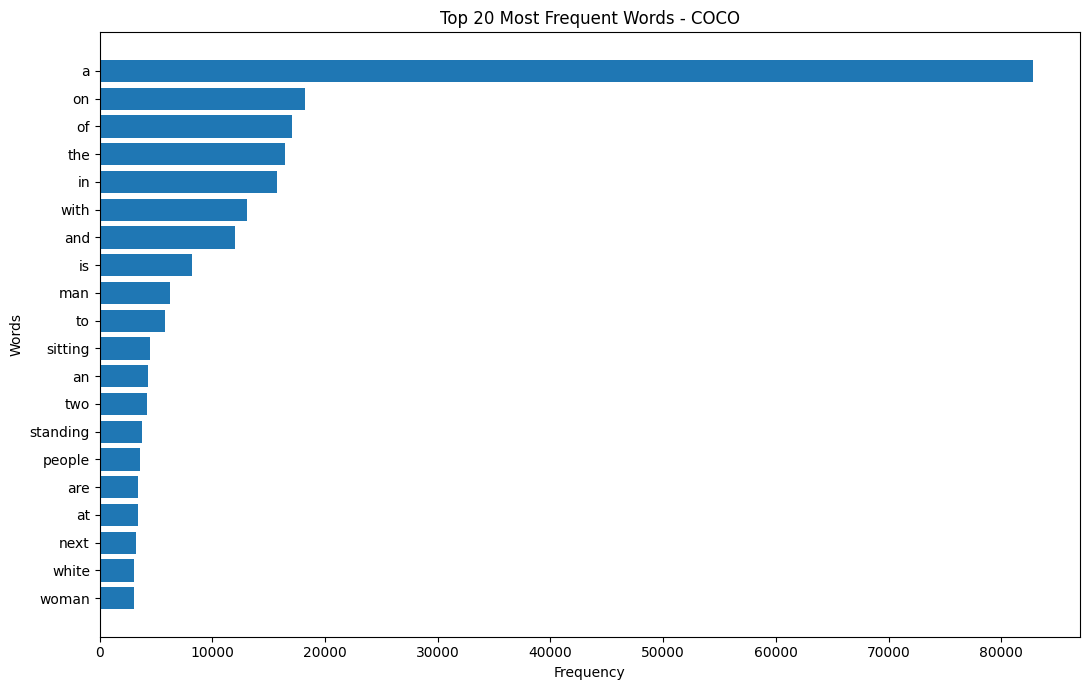

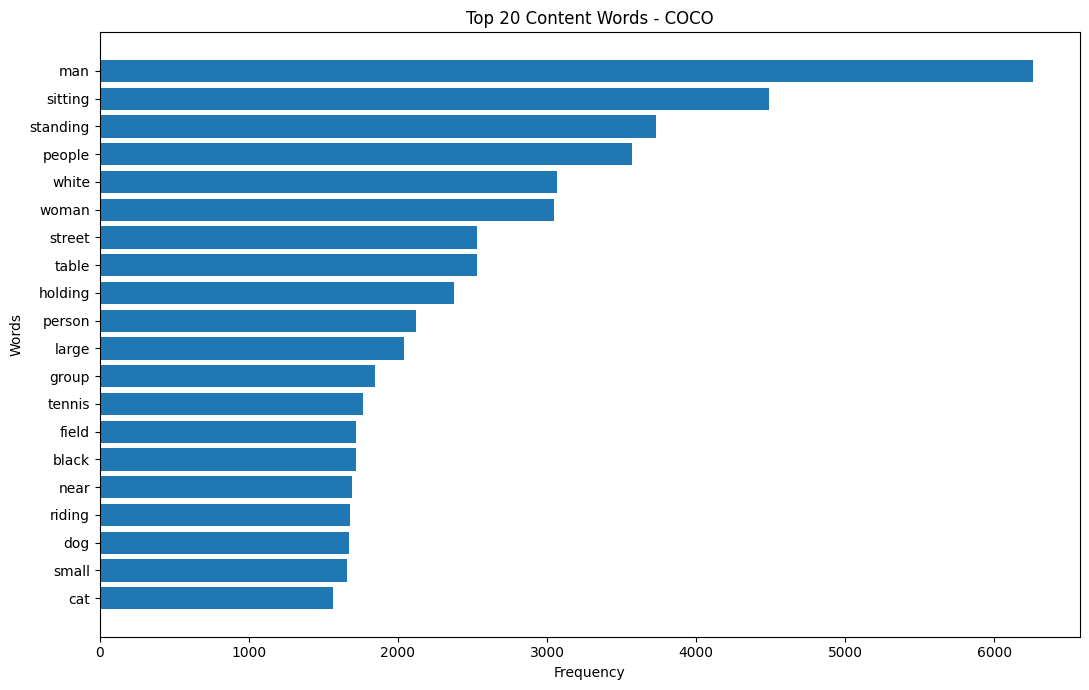

✅ Both charts saved successfully!


In [ ]:
import matplotlib.pyplot as plt

# Plot 1: Raw word frequencies
raw_top20 = pd.DataFrame(
    word_counts.most_common(20),
    columns=["word", "frequency"]
)

plt.figure(figsize=(11, 7))

plt.barh(
    raw_top20["word"][::-1],
    raw_top20["frequency"][::-1]
)

plt.title("Top 20 Most Frequent Words - COCO")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()

plt.savefig(
    eda_dir / "top_20_words_raw.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Plot 2: Content word frequencies
plt.figure(figsize=(11, 7))

plt.barh(
    content_df["word"][::-1],
    content_df["frequency"][::-1]
)

plt.title("Top 20 Content Words - COCO")
plt.xlabel("Frequency")
plt.ylabel("Words")
plt.tight_layout()

plt.savefig(
    eda_dir / "top_20_content_words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Both charts saved successfully!")

## 4. Parts of speech

In [ ]:
!pip -q install spacy
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 24.0 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
import spacy
import pandas as pd
import json
from collections import Counter, defaultdict

# Load English POS model
nlp = spacy.load(
    "en_core_web_sm",
    disable=["parser", "ner"]
)

# Load original captions
df_pos = pd.read_csv(
    DATA_DIR / "preprocessed_captions"
    / "kb_captions_retrieval.csv"
)

assert len(df_pos) == 50000
assert df_pos["caption_raw"].notna().all()

# Counters
pos_counts = Counter()
pos_terms = defaultdict(Counter)
per_caption_results = []

# Analyze captions efficiently in batches
captions = df_pos["caption_raw"].tolist()

for row, doc in zip(
    df_pos.itertuples(index=False),
    nlp.pipe(captions, batch_size=256)
):
    local_counts = Counter()

    for token in doc:

        # Ignore punctuation and whitespace
        if token.is_punct or token.is_space:
            continue

        pos_counts[token.pos_] += 1
        local_counts[token.pos_] += 1

        if token.is_alpha:
            pos_terms[token.pos_][
                token.lemma_.lower()
            ] += 1

    per_caption_results.append({
        "image_id": int(row.image_id),
        "annotation_id": int(row.annotation_id),
        "total_tokens": sum(local_counts.values()),
        "nouns": local_counts["NOUN"],
        "verbs": local_counts["VERB"],
        "adjectives": local_counts["ADJ"],
        "adpositions": local_counts["ADP"]
    })

print("✅ POS analysis completed!")

# Calculate numerical statistics
total_pos_tokens = sum(pos_counts.values())

pos_df = pd.DataFrame(
    pos_counts.most_common(),
    columns=["POS", "Frequency"]
)

pos_df["Percentage"] = (
    pos_df["Frequency"] / total_pos_tokens * 100
).round(2)

# Save full POS distribution
pos_df.to_csv(
    eda_dir / "pos_distribution.csv",
    index=False
)

# Save per-caption statistics
pd.DataFrame(per_caption_results).to_csv(
    eda_dir / "caption_pos_counts.csv",
    index=False
)

# Save all term frequencies by POS category
term_rows = [
    {"POS": pos, "lemma": word, "frequency": freq}
    for pos, terms in pos_terms.items()
    for word, freq in terms.items()
]

pd.DataFrame(term_rows).to_csv(
    eda_dir / "pos_term_frequencies.csv",
    index=False
)

# Save JSON summary
pos_stats = {
    "total_captions": len(df_pos),
    "total_pos_tokens": total_pos_tokens,
    "model": "en_core_web_sm",
    "model_version": nlp.meta.get("version"),
    "source": "caption_raw",
    "excluded": ["punctuation", "whitespace"],
    "pos_distribution": dict(pos_counts)
}

with open(
    eda_dir / "pos_statistics.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(pos_stats, f, indent=4)

print("\n===== POS DISTRIBUTION =====")
print(pos_df.to_string(index=False))

print("\n✅ Numerical results saved!")

✅ POS analysis completed!

===== POS DISTRIBUTION =====
  POS  Frequency  Percentage
 NOUN     181109       34.54
  DET     107689       20.54
  ADP      89040       16.98
 VERB      49074        9.36
  ADJ      37239        7.10
  AUX      14267        2.72
CCONJ      12189        2.32
 PRON      11089        2.11
  ADV       7461        1.42
  NUM       6607        1.26
PROPN       4748        0.91
 PART       2183        0.42
SCONJ       1542        0.29
 INTJ         69        0.01
    X         43        0.01
  SYM          6        0.00
PUNCT          2        0.00

✅ Numerical results saved!


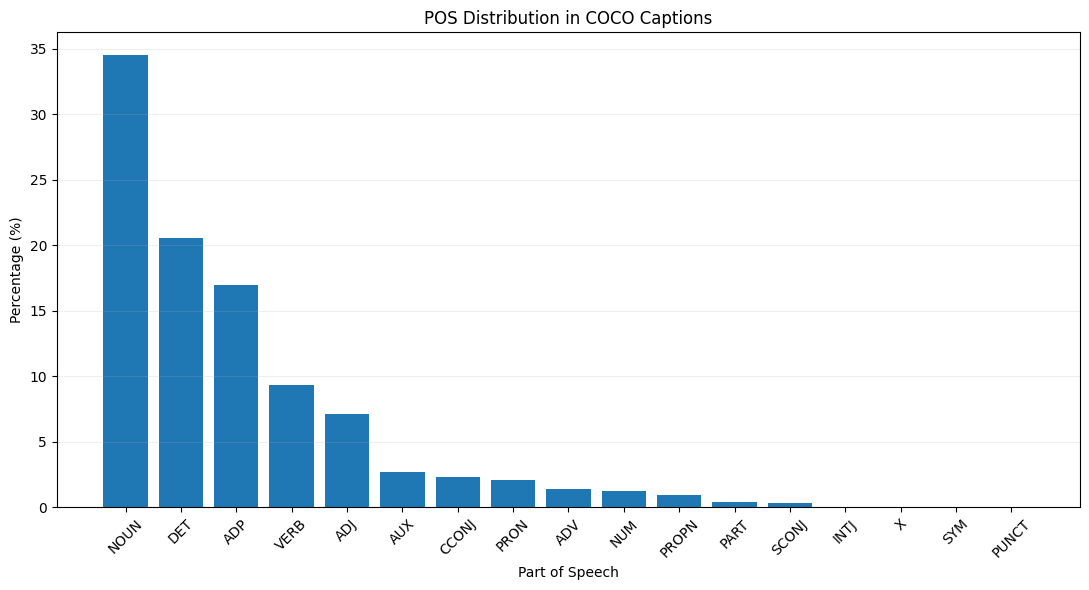

✅ POS distribution chart saved!


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))

plt.bar(
    pos_df["POS"],
    pos_df["Percentage"]
)

plt.title("POS Distribution in COCO Captions")
plt.xlabel("Part of Speech")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()

plt.savefig(
    eda_dir / "pos_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ POS distribution chart saved!")

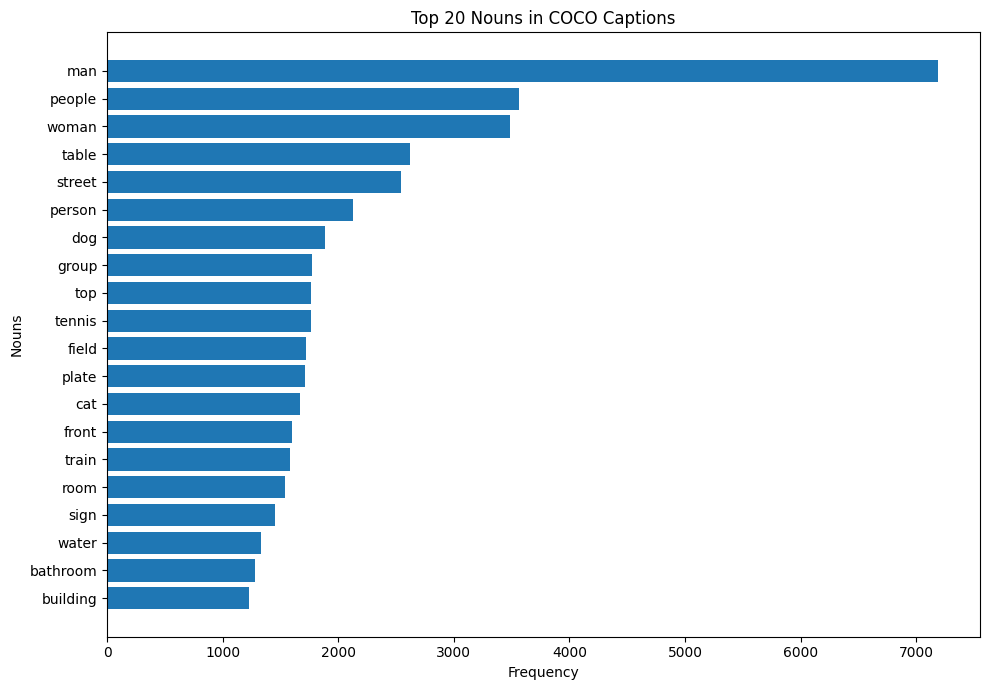

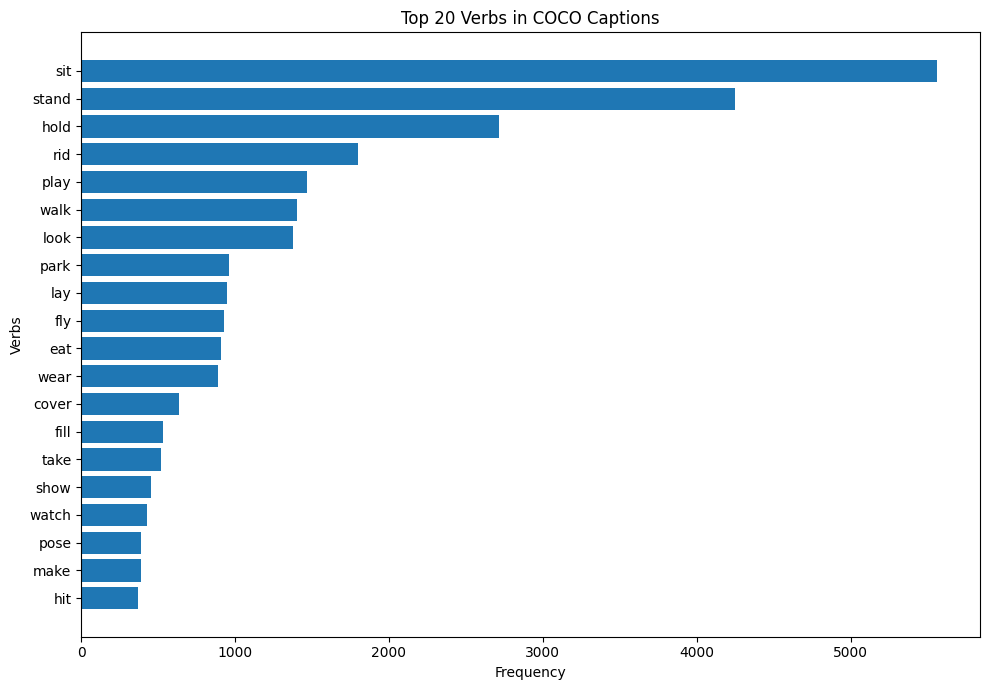

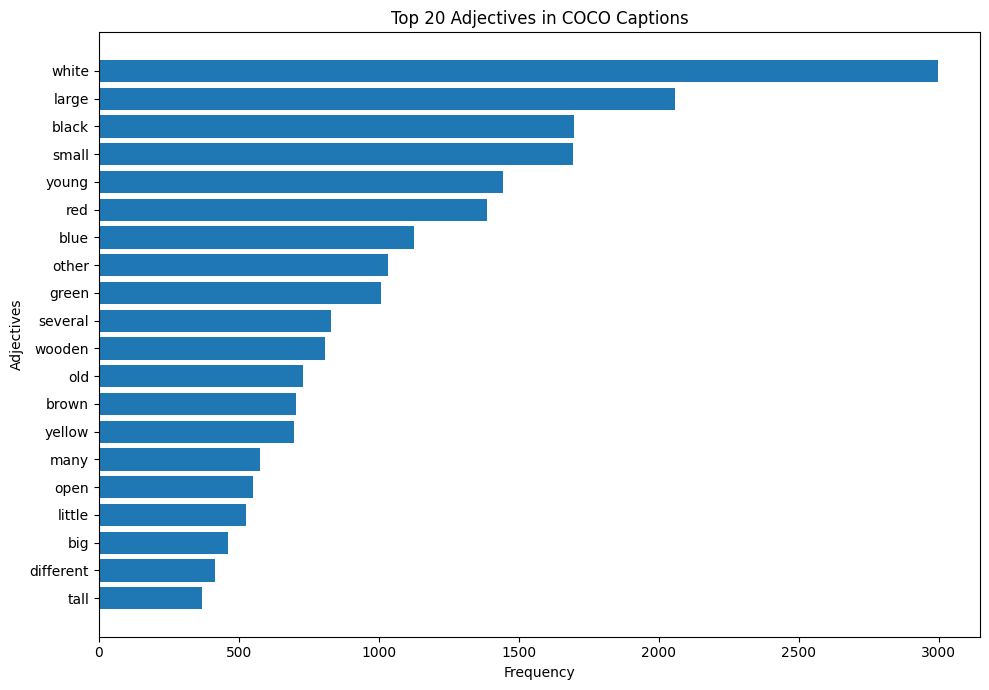

✅ All POS charts and statistics saved!


In [ ]:
categories = {
    "NOUN": "Nouns",
    "VERB": "Verbs",
    "ADJ": "Adjectives"
}

for pos_tag, label in categories.items():

    top_terms = pd.DataFrame(
        pos_terms[pos_tag].most_common(20),
        columns=["word", "frequency"]
    )

    # Save numerical frequencies
    top_terms.to_csv(
        eda_dir / f"top_20_{label.lower()}.csv",
        index=False
    )

    # Create plot
    plt.figure(figsize=(10, 7))

    plt.barh(
        top_terms["word"][::-1],
        top_terms["frequency"][::-1]
    )

    plt.title(f"Top 20 {label} in COCO Captions")
    plt.xlabel("Frequency")
    plt.ylabel(label)
    plt.tight_layout()

    plt.savefig(
        eda_dir / f"top_20_{label.lower()}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

print("✅ All POS charts and statistics saved!")

## 5. Objects in the images

From the human COCO labels.

In [ ]:
import json
import pandas as pd
from collections import Counter, defaultdict

# Step 1: Load COCO object annotations
instances_path = (
    DATA_DIR / "approved_annotations"
    / "kb_instances.json"
)

with open(instances_path, "r") as f:
    instances = json.load(f)

# Step 2: Verify Knowledge Base IDs
with open(SPLITS_DIR / "split_ids.json") as f:
    splits = json.load(f)

kb_ids = set(map(int, splits["knowledge_base"]))

assert len(kb_ids) == 10000
assert {img["id"] for img in instances["images"]} == kb_ids

# Step 3: Map category IDs to names
categories = {
    cat["id"]: cat["name"]
    for cat in instances["categories"]
}

# Step 4: Count objects
object_counts = Counter()
category_counts = Counter()
image_categories = defaultdict(set)
category_images = defaultdict(set)

for ann in instances["annotations"]:

    image_id = ann["image_id"]
    category_id = ann["category_id"]

    assert image_id in kb_ids
    assert category_id in categories

    object_counts[image_id] += 1
    category_counts[category_id] += 1

    image_categories[image_id].add(
        categories[category_id]
    )
    category_images[category_id].add(image_id)

# Step 5: Create per-image metadata
metadata_rows = []

for image_id in sorted(kb_ids):

    names = sorted(image_categories[image_id])

    metadata_rows.append({
        "image_id": image_id,
        "object_count": object_counts[image_id],
        "distinct_categories": len(names),
        "object_categories": json.dumps(names)
    })

metadata_df = pd.DataFrame(metadata_rows)

# Step 6: Create category statistics
category_rows = []

for category_id, name in categories.items():

    category_rows.append({
        "category_id": category_id,
        "category_name": name,
        "instance_count": category_counts[category_id],
        "image_count": len(category_images[category_id])
    })

category_df = pd.DataFrame(category_rows)

category_df = category_df.sort_values(
    "instance_count", ascending=False
)

# Step 7: Calculate summary statistics
object_stats = {
    "total_images": len(kb_ids),
    "total_annotated_objects": len(
        instances["annotations"]
    ),
    "categories_present": int(
        (category_df["instance_count"] > 0).sum()
    ),
    "average_objects_per_image": round(
        float(metadata_df["object_count"].mean()), 2
    ),
    "median_objects_per_image": float(
        metadata_df["object_count"].median()
    ),
    "min_objects_per_image": int(
        metadata_df["object_count"].min()
    ),
    "max_objects_per_image": int(
        metadata_df["object_count"].max()
    ),
    "images_without_annotations": int(
        (metadata_df["object_count"] == 0).sum()
    ),
    "annotation_source": "COCO instances_train2017"
}

# Step 8: Save everything
metadata_dir = DATA_DIR / "metadata"
metadata_dir.mkdir(parents=True, exist_ok=True)

metadata_df.to_csv(
    metadata_dir / "kb_object_metadata.csv",
    index=False
)

category_df.to_csv(
    eda_dir / "object_category_distribution.csv",
    index=False
)

category_df.head(50).to_csv(
    eda_dir / "top_50_object_categories.csv",
    index=False
)

with open(
    eda_dir / "object_statistics.json",
    "w"
) as f:
    json.dump(object_stats, f, indent=4)

# Step 9: Display results
print("===== OBJECT STATISTICS =====")

for key, value in object_stats.items():
    print(f"{key}: {value}")

print("\n===== TOP 10 OBJECT CATEGORIES =====")
print(category_df.head(10).to_string(index=False))

print("\n✅ Object statistics and metadata saved!")

===== OBJECT STATISTICS =====
total_images: 10000
total_annotated_objects: 72062
categories_present: 80
average_objects_per_image: 7.21
median_objects_per_image: 4.0
min_objects_per_image: 0
max_objects_per_image: 56
images_without_annotations: 102
annotation_source: COCO instances_train2017

===== TOP 10 OBJECT CATEGORIES =====
 category_id category_name  instance_count  image_count
           1        person           22085         5421
           3           car            3619         1000
          62         chair            3180         1058
          44        bottle            2045          718
          84          book            2003          447
          47           cup            1658          752
          67  dining table            1273          971
          51          bowl            1225          564
          28      umbrella            1090          350
          31       handbag            1011          561

✅ Object statistics and metadata saved!


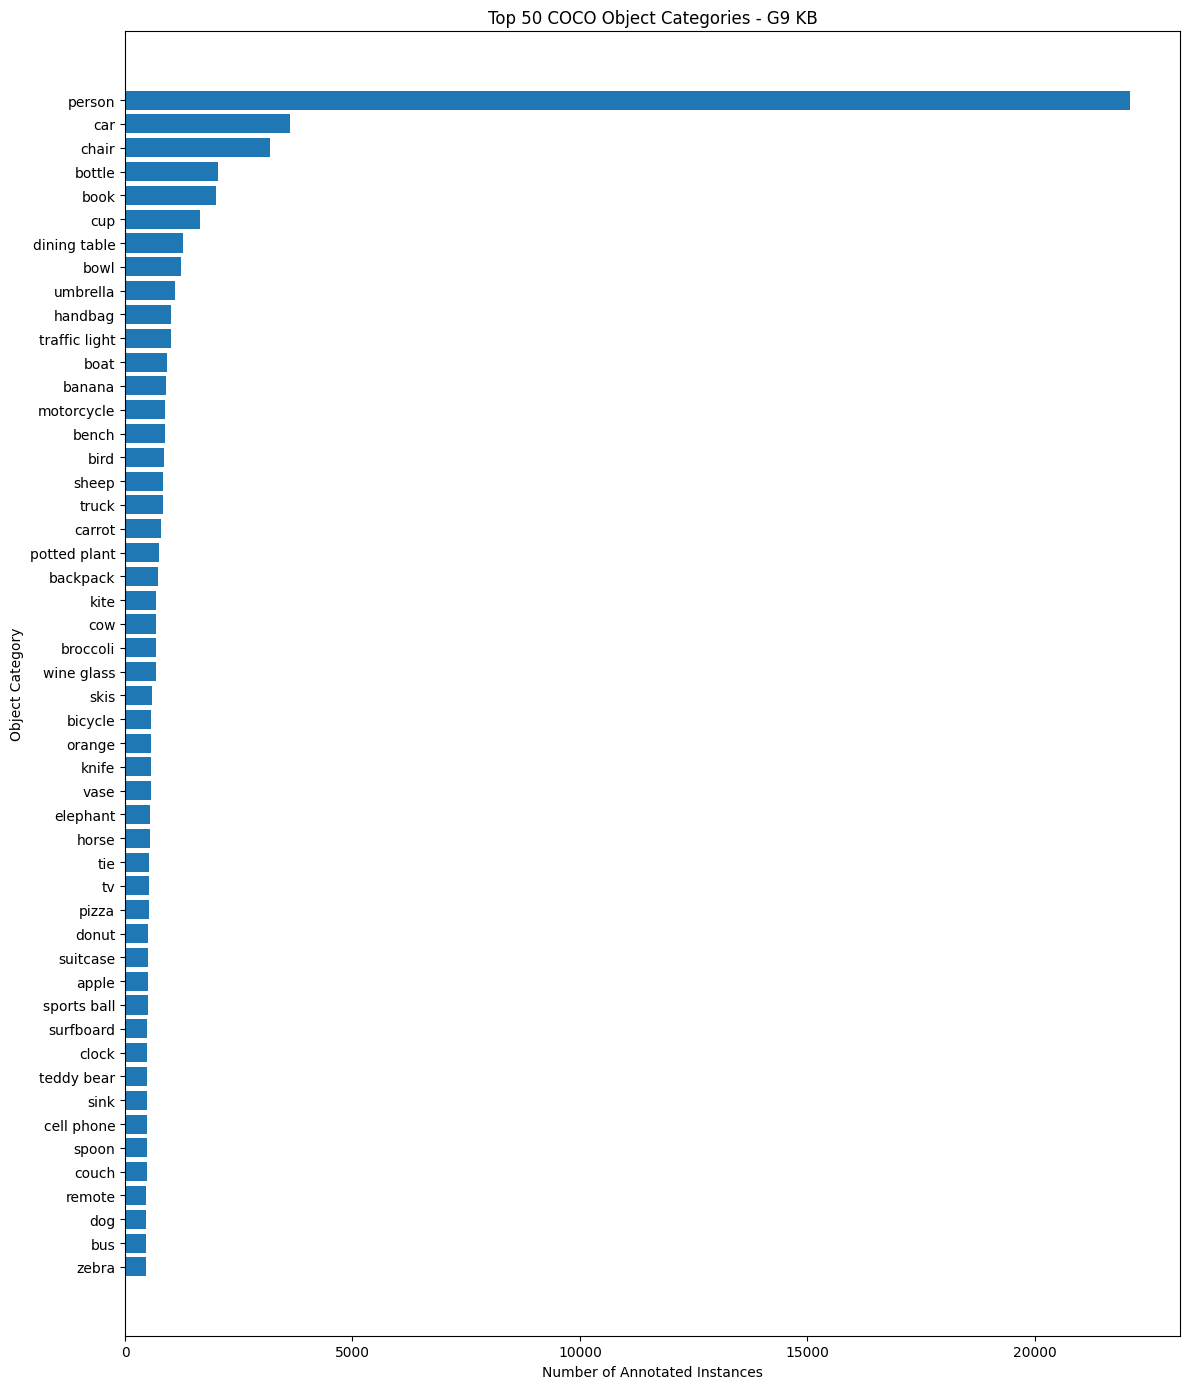

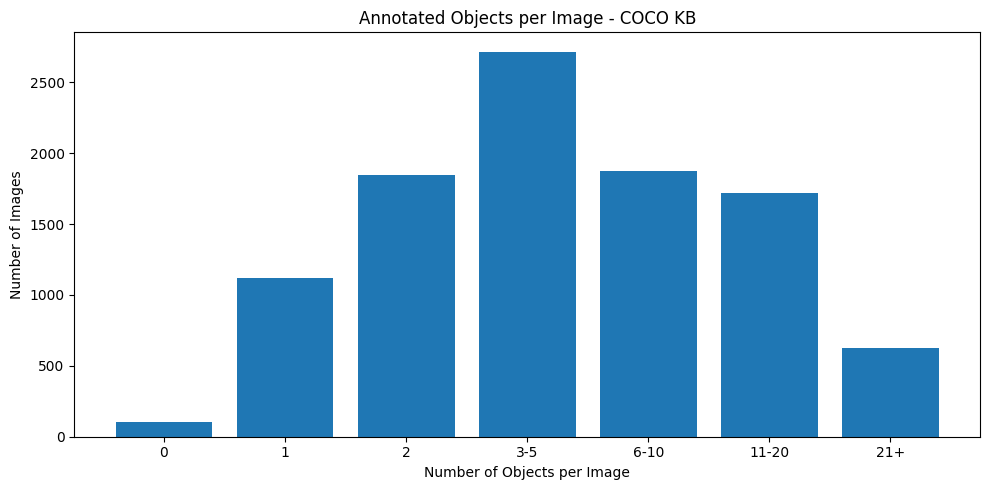

✅ Both charts and numerical data saved!


In [ ]:
import matplotlib.pyplot as plt

# Chart 1: Top 50 object categories
top50 = category_df.head(50).iloc[::-1]

plt.figure(figsize=(12, 14))

plt.barh(
    top50["category_name"],
    top50["instance_count"]
)

plt.title("Top 50 COCO Object Categories - G9 KB")
plt.xlabel("Number of Annotated Instances")
plt.ylabel("Object Category")
plt.tight_layout()

plt.savefig(
    eda_dir / "top_50_object_categories.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Chart 2: Objects per image distribution
bins = [-1, 0, 1, 2, 5, 10, 20, float("inf")]
labels = ["0", "1", "2", "3-5",
          "6-10", "11-20", "21+"]

groups = pd.cut(
    metadata_df["object_count"],
    bins=bins,
    labels=labels
)

distribution = (
    groups.value_counts()
    .reindex(labels, fill_value=0)
)

distribution.to_csv(
    eda_dir / "object_count_distribution.csv",
    header=["image_count"]
)

plt.figure(figsize=(10, 5))

plt.bar(
    distribution.index.astype(str),
    distribution.values
)

plt.title("Annotated Objects per Image - COCO KB")
plt.xlabel("Number of Objects per Image")
plt.ylabel("Number of Images")
plt.tight_layout()

plt.savefig(
    eda_dir / "objects_per_image_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Both charts and numerical data saved!")

## 6. Objects that appear together

Count and Jaccard similarity for every pair of categories.

In [ ]:
import pandas as pd
import numpy as np
import json

from collections import Counter
from itertools import combinations

# Step 1: Load saved object metadata
metadata_path = (
    DATA_DIR / "metadata" / "kb_object_metadata.csv"
)

eda_dir = PROJECT_DIR / "results" / "eda"
eda_dir.mkdir(parents=True, exist_ok=True)

meta = pd.read_csv(metadata_path)

assert len(meta) == 10000
assert meta["image_id"].nunique() == 10000

# Step 2: Convert JSON strings to Python lists
image_objects = [
    sorted(set(json.loads(value)))
    for value in meta["object_categories"]
]

# Step 3: Count images containing each category
image_frequency = Counter()

# Count images containing each pair
pair_frequency = Counter()

for objects in image_objects:

    for obj in objects:
        image_frequency[obj] += 1

    for pair in combinations(objects, 2):
        pair_frequency[pair] += 1

# Step 4: Create complete count matrix
classes = sorted(image_frequency)

co_matrix = pd.DataFrame(
    0,
    index=classes,
    columns=classes,
    dtype=int
)

for obj, count in image_frequency.items():
    co_matrix.loc[obj, obj] = count

for (obj_a, obj_b), count in pair_frequency.items():
    co_matrix.loc[obj_a, obj_b] = count
    co_matrix.loc[obj_b, obj_a] = count

# Step 5: Calculate Jaccard similarity
jaccard = pd.DataFrame(
    0.0,
    index=classes,
    columns=classes
)

for obj in classes:
    jaccard.loc[obj, obj] = 1.0

pair_rows = []

for (obj_a, obj_b), count in pair_frequency.items():

    union = (
        image_frequency[obj_a]
        + image_frequency[obj_b]
        - count
    )

    score = count / union

    jaccard.loc[obj_a, obj_b] = score
    jaccard.loc[obj_b, obj_a] = score

    pair_rows.append({
        "object_a": obj_a,
        "object_b": obj_b,
        "cooccurrence_count": count,
        "jaccard_similarity": round(score, 5)
    })

pairs_df = pd.DataFrame(pair_rows)

pairs_df = pairs_df.sort_values(
    ["cooccurrence_count", "object_a", "object_b"],
    ascending=[False, True, True]
)

# Step 6: Calculate summary statistics
co_stats = {
    "total_images": len(meta),
    "total_object_categories": len(classes),
    "unique_observed_pairs": len(pair_frequency),
    "images_with_multiple_categories": sum(
        len(objects) >= 2 for objects in image_objects
    ),
    "cooccurrence_definition":
        "Two distinct COCO object categories "
        "annotated in the same image",
    "similarity_metric": "Jaccard"
}

# Step 7: Save all numerical results
co_matrix.to_csv(
    eda_dir / "object_cooccurrence_counts.csv"
)

jaccard.to_csv(
    eda_dir / "object_cooccurrence_jaccard.csv"
)

pairs_df.to_csv(
    eda_dir / "object_pairs_full.csv",
    index=False
)

pairs_df.head(20).to_csv(
    eda_dir / "top_20_object_pairs.csv",
    index=False
)

with open(
    eda_dir / "cooccurrence_statistics.json",
    "w"
) as f:
    json.dump(co_stats, f, indent=4)

# Step 8: Display results
print("===== CO-OCCURRENCE STATISTICS =====")

for key, value in co_stats.items():
    print(f"{key}: {value}")

print("\n===== TOP 20 OBJECT PAIRS =====")
print(pairs_df.head(20).to_string(index=False))

print("\n✅ All numerical results saved!")

===== CO-OCCURRENCE STATISTICS =====
total_images: 10000
total_object_categories: 80
unique_observed_pairs: 1864
images_with_multiple_categories: 7865
cooccurrence_definition: Two distinct COCO object categories annotated in the same image
similarity_metric: Jaccard

===== TOP 20 OBJECT PAIRS =====
    object_a      object_b  cooccurrence_count  jaccard_similarity
         car        person                 692             0.12079
       chair        person                 671             0.11553
     handbag        person                 510             0.09320
dining table        person                 495             0.08394
    backpack        person                 443             0.08111
      bottle        person                 406             0.07082
       chair  dining table                 399             0.24479
         cup        person                 384             0.06633
         cup  dining table                 372             0.27535
      person   sports ball    

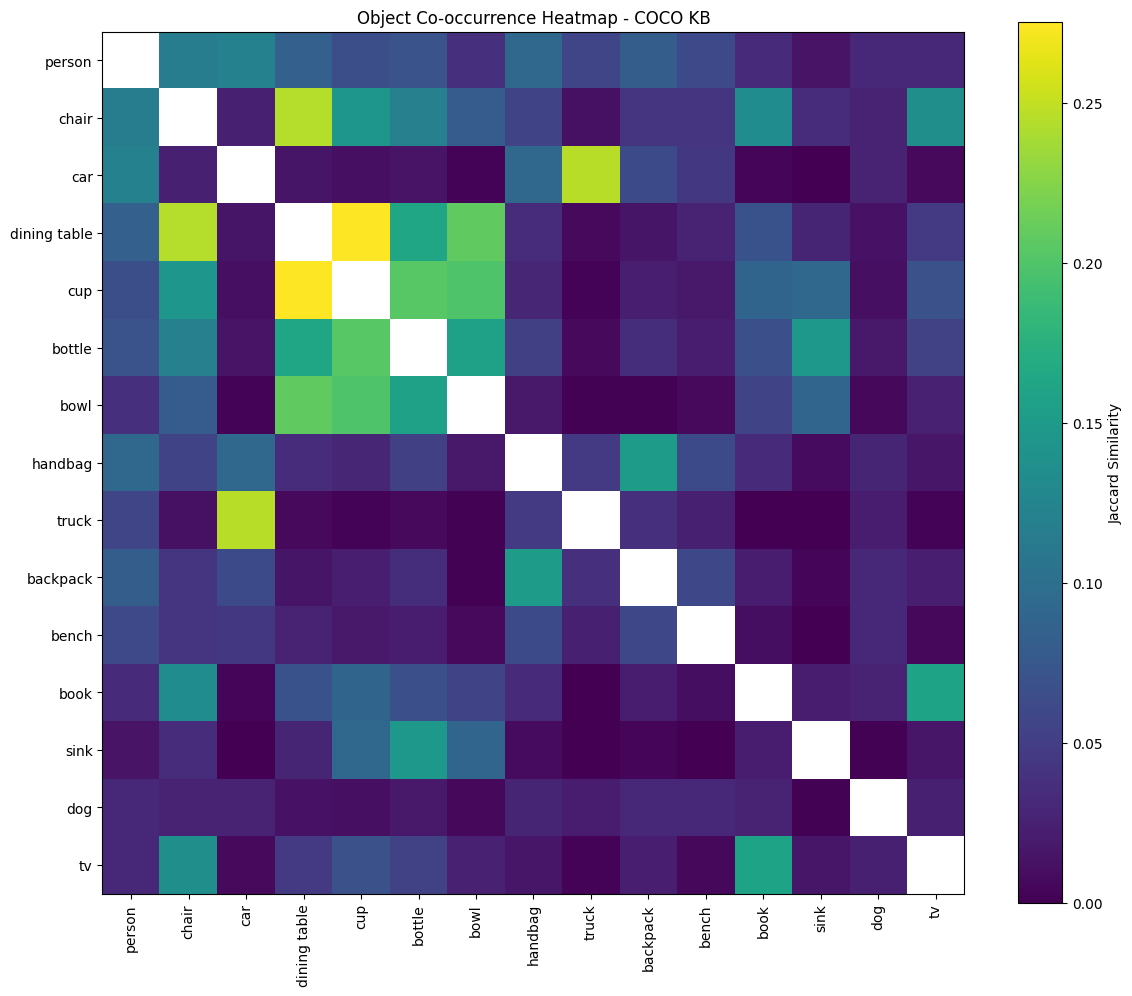

✅ Heatmap saved successfully!


In [ ]:
import matplotlib.pyplot as plt

# Step 1: Select 15 most common categories
top_classes = [
    name for name, count
    in image_frequency.most_common(15)
]

# Step 2: Extract Jaccard submatrix
heatmap_data = jaccard.loc[
    top_classes, top_classes
].to_numpy().copy()

# Hide self-comparison diagonal
np.fill_diagonal(heatmap_data, np.nan)

# Step 3: Create heatmap
plt.figure(figsize=(12, 10))

plt.imshow(
    heatmap_data,
    interpolation="nearest"
)

plt.colorbar(label="Jaccard Similarity")

plt.xticks(
    range(len(top_classes)),
    top_classes,
    rotation=90
)

plt.yticks(
    range(len(top_classes)),
    top_classes
)

plt.title(
    "Object Co-occurrence Heatmap - COCO KB"
)

plt.tight_layout()

# Step 4: Save high-resolution figure
plt.savefig(
    eda_dir / "object_cooccurrence_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("✅ Heatmap saved successfully!")

## 7. Scene complexity

Groups by number of labelled objects.

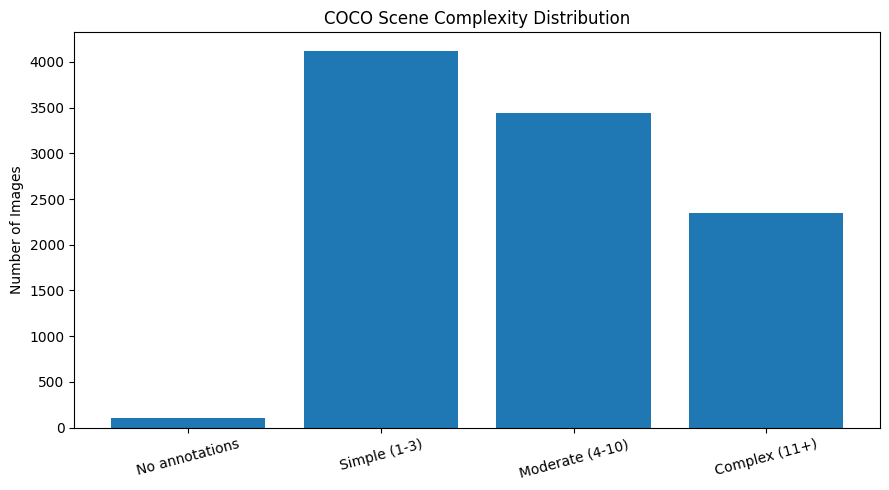

===== SCENE COMPLEXITY =====
complexity
No annotations      102
Simple (1-3)       4118
Moderate (4-10)    3436
Complex (11+)      2344
Name: count, dtype: int64

✅ Results and figure saved!


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import json

# Load saved metadata
df_scene = pd.read_csv(
    DATA_DIR / "metadata/kb_object_metadata.csv"
)

# Define complexity using annotated object counts
def complexity(n):
    if n == 0:
        return "No annotations"
    if n <= 3:
        return "Simple (1-3)"
    if n <= 10:
        return "Moderate (4-10)"
    return "Complex (11+)"

df_scene["complexity"] = df_scene["object_count"].apply(complexity)

order = [
    "No annotations",
    "Simple (1-3)",
    "Moderate (4-10)",
    "Complex (11+)"
]

distribution = df_scene["complexity"].value_counts().reindex(
    order, fill_value=0
)

# Save numerical results
stats = {
    "total_images": len(df_scene),
    "average_objects": float(df_scene["object_count"].mean()),
    "median_objects": float(df_scene["object_count"].median()),
    "average_categories": float(df_scene["distinct_categories"].mean()),
    "object_count_percentiles": {
        str(p): float(df_scene["object_count"].quantile(p / 100))
        for p in [25, 50, 75, 90, 95, 99]
    },
    "complexity_distribution": distribution.to_dict(),
    "complexity_definition": "Heuristic based on COCO annotated object counts"
}

with open(eda_dir / "scene_complexity_stats.json", "w") as f:
    json.dump(stats, f, indent=4)

df_scene.to_csv(
    eda_dir / "scene_complexity_per_image.csv",
    index=False
)

distribution.rename_axis("complexity").reset_index(
    name="image_count"
).to_csv(
    eda_dir / "scene_complexity_distribution.csv",
    index=False
)

# Save figure
plt.figure(figsize=(9, 5))
plt.bar(distribution.index, distribution.values)
plt.title("COCO Scene Complexity Distribution")
plt.ylabel("Number of Images")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(
    eda_dir / "scene_complexity.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("===== SCENE COMPLEXITY =====")
print(distribution)
print("\n✅ Results and figure saved!")

## 8. Colours and context in captions

In [ ]:
# Caption keyword cues: colours and scene context.
# These are text heuristics, NOT visual ground truth.
import pandas as pd
from collections import Counter

caps = pd.read_csv(DATA_DIR / "preprocessed_captions" / "kb_captions_retrieval.csv")

colors = ['black','white','red','blue','green','yellow','brown','orange','pink','purple','gray','grey']
contexts = {
    'indoor_cue': ['indoor','indoors','kitchen','bathroom','bedroom','living room'],
    'outdoor_cue': ['outdoor','outdoors','street','beach','mountain','park','field'],
    'night_cue': ['night','nighttime','evening'],
    'day_cue': ['daytime','daylight','sunny','morning'],
}

cues = {c: Counter() for c in ['colors', 'contexts']}
for row in caps.itertuples(index=False):
    text = ' ' + str(row.caption_clean).lower() + ' '
    tokens = set(text.split())
    for color in colors:
        if color in tokens:
            cues['colors'][color] += 1
    for ctx, terms in contexts.items():
        if any((' ' + x + ' ') in text for x in terms):
            cues['contexts'][ctx] += 1

for name, counts in cues.items():
    pd.DataFrame(counts.most_common(), columns=['cue', 'caption_count']).to_csv(
        eda_dir / f'{name}_caption_cues.csv', index=False)
    print(name, dict(counts.most_common()))

## 9. Box geometry between objects

In [ ]:
# Bounding-box geometry between object pairs.
# These are geometric proxies, NOT semantic relations like "on" or "next to".
import json
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from itertools import combinations

with open(DATA_DIR / "approved_annotations" / "kb_instances.json") as f:
    inst = json.load(f)

by_image = defaultdict(list)
for a in inst['annotations']:
    if a.get('iscrowd', 0):
        continue
    x, y, w, h = a['bbox']
    if w > 0 and h > 0:
        by_image[a['image_id']].append((x, y, w, h))

spatial = Counter()
for boxes in by_image.values():
    for (x1, y1, w1, h1), (x2, y2, w2, h2) in combinations(boxes, 2):
        spatial['pair_count'] += 1
        if abs((x1 + w1/2) - (x2 + w2/2)) > (w1 + w2) / 4:
            spatial['horizontal_center_separation'] += 1
        if abs((y1 + h1/2) - (y2 + h2/2)) > (h1 + h2) / 4:
            spatial['vertical_center_separation'] += 1
        if min(x1 + w1, x2 + w2) > max(x1, x2) and min(y1 + h1, y2 + h2) > max(y1, y2):
            spatial['overlapping_bboxes'] += 1

pd.DataFrame(list(spatial.items()), columns=['proxy', 'count']).to_csv(
    eda_dir / 'spatial_bbox_proxy_counts.csv', index=False)

fig, ax = plt.subplots(figsize=(8, 4))
keys = [k for k in spatial if k != 'pair_count']
ax.bar(keys, [spatial[k] for k in keys])
ax.tick_params(axis='x', labelrotation=20)
ax.set_ylabel('Object-pair count')
ax.set_title('Bounding-box geometry proxies (not semantic relationships)')
fig.tight_layout()
fig.savefig(eda_dir / 'spatial_bbox_proxies.png', dpi=300, bbox_inches='tight')
plt.show()
print(dict(spatial))